# Prerequisite 04B · 概率、采样与蒙特卡洛

[上一章：数学](Prerequisite04_Math.ipynb) · [预备篇导航](Prerequisite00_Index.ipynb) · [下一章：机器学习](Prerequisite05_Machine_Learning.ipynb)

**为什么单独补这一课：**强化学习里几乎每个量都是随机的——策略随机选动作，环境随机转移，回报因此也是随机变量。
原书默认你熟悉概率；没有机器学习背景时，这是最容易“看公式像天书”的地方。

**学完你应该能：**

- 把“概率分布”“采样”“期望”“方差”翻译成 NumPy 代码；
- 理解为什么用**样本平均**来估计期望（蒙特卡洛），以及为什么样本越多越准；
- 看懂 $P(s'\mid s,a)$、$\pi(a\mid s)$ 这类条件概率记号；
- 解释为什么策略梯度用 `log_prob`，PPO 用概率比 `ratio`。

建议时长：3–5 小时。不要求证明，只要求会算、会写、会解释。


## 1. 随机变量与分布：先会“掷骰子”

**随机变量**就是“结果不确定的数”。**分布**告诉你每个结果出现的概率，所有概率加起来等于 1。

| 生活例子 | RL 中的对应物 |
|---|---|
| 掷骰子得到 1–6 | 策略在 4 个动作里随机选一个 |
| 抽奖中奖金额 | 一个 episode 的总回报 |
| 天气：晴/雨 | 冰面上“想往右走，实际滑到了下面” |

在代码里，“采样”就是按分布随机抽一个结果。下面用 `rng.choice` 模拟一个不公平的三面骰子。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
outcomes = np.array([-1.0, 0.0, 2.0])      # 三种可能的奖励
probs = np.array([0.2, 0.5, 0.3])          # 对应概率，和为 1

samples = rng.choice(outcomes, size=10, p=probs)
print("10 次采样:", samples)

big = rng.choice(outcomes, size=100_000, p=probs)
for value, p in zip(outcomes, probs):
    print(f"结果 {value:+.0f}: 真实概率 {p:.2f}, 10 万次中出现的频率 {np.mean(big == value):.3f}")


10 次采样: [ 0.  0. -1. -1.  2.  2.  0.  2.  0.  2.]
结果 -1: 真实概率 0.20, 10 万次中出现的频率 0.201
结果 +0: 真实概率 0.50, 10 万次中出现的频率 0.500
结果 +2: 真实概率 0.30, 10 万次中出现的频率 0.299


**观察：**采样次数少时频率乱跳；次数多时频率接近真实概率。这叫**大数定律**，它是“用经验学习”的根本依据。

## 2. 期望：概率加权平均，以及“用样本平均来估计它”

$$\mathbb E[X]=\sum_x p(x)\,x$$

- 如果你**知道**分布（像 Chapter05 的动态规划），就直接按公式加权求和；
- 如果你**不知道**分布（大多数 RL 场景），就采样很多次取平均——这叫**蒙特卡洛估计**。

下面画出“样本平均随样本数变化”的曲线：它会越来越贴近真实期望 0.4。


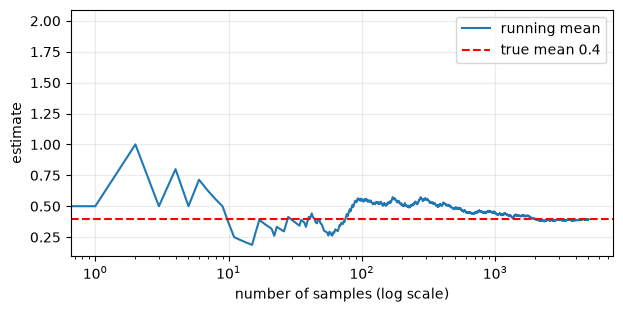

真实期望: 0.4  用 5000 个样本估计: 0.3928


In [2]:
true_mean = np.sum(probs * outcomes)
running_mean = np.cumsum(big[:5000]) / np.arange(1, 5001)

plt.figure(figsize=(7, 3.2))
plt.plot(running_mean, label="running mean")
plt.axhline(true_mean, color="red", linestyle="--", label=f"true mean {true_mean:.1f}")
plt.xscale("log"); plt.xlabel("number of samples (log scale)"); plt.ylabel("estimate")
plt.legend(); plt.grid(alpha=.25); plt.show(); plt.close()
print("真实期望:", round(true_mean, 4), " 用 5000 个样本估计:", round(running_mean[-1], 4))


## 3. 方差与标准误：估计“有多不靠谱”

- **方差** $\mathrm{Var}[X]=\mathbb E[(X-\mathbb E X)^2]$：单个样本离平均值有多远。
- **标准误** $\mathrm{SE}=\sigma/\sqrt n$：用 $n$ 个样本求平均后，平均值本身还会抖多少。

关键结论：**误差按 $1/\sqrt n$ 缩小**。想把误差减半，样本要变成 4 倍。这解释了 RL 为什么那么“吃样本”，
也解释了后面各种“降低方差”的技巧（baseline、advantage、GAE）为什么重要。


In [3]:
true_std = np.sqrt(np.sum(probs * (outcomes - true_mean) ** 2))
print("单个样本的标准差:", round(true_std, 3))
for n in (10, 100, 1000, 10000):
    # 重复做 500 次“取 n 个样本求平均”，看这些平均值本身散得多开
    means = rng.choice(outcomes, size=(500, n), p=probs).mean(axis=1)
    print(f"n={n:>5}: 平均值的实际波动 {means.std():.4f}   理论 σ/√n = {true_std/np.sqrt(n):.4f}")


单个样本的标准差: 1.114
n=   10: 平均值的实际波动 0.3753   理论 σ/√n = 0.3521
n=  100: 平均值的实际波动 0.1089   理论 σ/√n = 0.1114
n= 1000: 平均值的实际波动 0.0363   理论 σ/√n = 0.0352
n=10000: 平均值的实际波动 0.0109   理论 σ/√n = 0.0111


## 4. 条件概率：读懂 $P(s'\mid s,a)$ 与 $\pi(a\mid s)$

竖线 “$\mid$” 读作“在……条件下”。

- $\pi(a\mid s)$：**在状态 $s$ 下**，策略选动作 $a$ 的概率。每个状态各有一个分布。
- $P(s'\mid s,a)$：**在状态 $s$ 做动作 $a$ 后**，环境转到 $s'$ 的概率。

在代码里，条件分布通常就是一张表：**每一行是一个条件，行内概率和为 1**。


In [4]:
# 3 个状态、2 个动作的策略表：policy[s] 是在状态 s 下两个动作的概率
policy = np.array([[0.9, 0.1],
                   [0.5, 0.5],
                   [0.2, 0.8]])
assert np.allclose(policy.sum(axis=1), 1.0), "每一行（每个条件）概率之和必须为 1"

state = 2
action = rng.choice(2, p=policy[state])
print(f"在状态 {state} 下按 π(a|s)={policy[state]} 采样到动作 {action}")

# 一条轨迹（只考虑策略部分）的概率 = 每一步概率的乘积
visited = [(0, 0), (1, 1), (2, 1)]  # (state, action)
prob = np.prod([policy[s, a] for s, a in visited])
log_prob = np.sum([np.log(policy[s, a]) for s, a in visited])
print("轨迹概率:", prob, " log 概率:", round(log_prob, 4), " exp(log)=", round(np.exp(log_prob), 4))


在状态 2 下按 π(a|s)=[0.2 0.8] 采样到动作 1
轨迹概率: 0.36000000000000004  log 概率: -1.0217  exp(log)= 0.36


**为什么用 log：**乘积变求和（求导更简单），而且很多小概率连乘会下溢成 0。Chapter11 的策略梯度
$\nabla_\theta \log \pi_\theta(a\mid s)$ 就从这里来。

## 5. 重要性采样：用“旧数据”评估“新策略”

如果样本来自分布 $q$，却想求分布 $p$ 下的期望，可以给每个样本乘上权重 $p(x)/q(x)$：

$$\mathbb E_{x\sim p}[f(x)]=\mathbb E_{x\sim q}\left[\frac{p(x)}{q(x)}f(x)\right]$$

- Chapter16 的 PPO 中，`ratio = π_new(a|s) / π_old(a|s)` 就是这个权重；
- Chapter08 的优先经验回放（PER）用重要性权重修正“不均匀抽样”带来的偏差。

权重差异越大，估计的方差越大——所以 PPO 要把 ratio“裁剪”在 $[1-\epsilon,1+\epsilon]$ 附近。


In [5]:
q_dist = np.array([0.5, 0.3, 0.2])     # 采样用的旧分布
p_dist = np.array([0.1, 0.2, 0.7])     # 想评估的新分布
f = np.array([1.0, 2.0, 10.0])

xs = rng.choice(3, size=50_000, p=q_dist)
naive = f[xs].mean()                              # 错：这是 q 下的期望
weighted = np.mean(p_dist[xs] / q_dist[xs] * f[xs])  # 对：重要性加权
print("p 下真实期望:", np.sum(p_dist * f))
print("直接平均（错误）:", round(naive, 3), " 重要性加权:", round(weighted, 3))


p 下真实期望: 7.5
直接平均（错误）: 3.099  重要性加权: 7.506


## 6. 常见误区

- **把一次运行的结果当结论。**单次回报是随机变量的一个样本，至少要多个随机种子。
- **把概率表的列当条件。**$P(s'\mid s,a)$ 的“条件”是 $(s,a)$，检查 `sum(axis=...)` 时要对“结果”那一维求和。
- **方差=误差。**方差描述随机性本身；估计的误差取决于方差**和**样本数。
- **log(0)。**概率为 0 时 log 为 $-\infty$；代码里通常给概率加极小值或直接使用 logits 计算。


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [6]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：离散分布的期望

实现 `expectation(probs, values)`：返回 $\mathbb E[X]=\sum_i p_i x_i$。
如果 `probs` 之和不是 1（允许 `1e-6` 误差），用 `raise ValueError` 拒绝。
这正是 Bellman 方程里“对下一状态做概率加权”的那一步。

<details><summary>提示（卡住 10 分钟再看）</summary>

先用 `np.isclose(np.sum(probs), 1.0, atol=1e-6)` 检查，再用 `np.sum(probs * values)`。

</details>


In [7]:
import numpy as np

def expectation(probs, values):
    probs = np.asarray(probs, dtype=float)
    values = np.asarray(values, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_expectation():
    assert abs(expectation([0.2, 0.5, 0.3], [-1, 0, 2]) - 0.4) < 1e-9, "期望应为 0.2*(-1)+0.5*0+0.3*2=0.4"
    assert abs(expectation([1.0], [7.0]) - 7.0) < 1e-9, "确定性分布的期望就是那个值"
    try:
        expectation([0.5, 0.6], [1, 2])
    except ValueError:
        pass
    else:
        raise AssertionError("概率之和为 1.1 时应抛出 ValueError")

check(test_expectation)


[未完成] test_expectation：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def expectation(probs, values):
    probs = np.asarray(probs, dtype=float)
    values = np.asarray(values, dtype=float)
    if not np.isclose(probs.sum(), 1.0, atol=1e-6):
        raise ValueError("probs 之和必须为 1")
    return float(np.sum(probs * values))
```

</details>


### 练习 2：样本均值与标准误

实现 `mean_and_stderr(samples)`，返回 `(样本均值, 标准误)`，其中标准误
$\mathrm{SE}=s/\sqrt n$，$s$ 是**样本标准差**（`ddof=1`）。

以后报告“5 个随机种子的平均回报”时，你需要的就是这两个数。

<details><summary>提示（卡住 10 分钟再看）</summary>

`np.std(x, ddof=1) / np.sqrt(len(x))`。只有一个样本时无法估计波动，返回 `float('nan')`。

</details>


In [8]:
import numpy as np

def mean_and_stderr(samples):
    x = np.asarray(samples, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_mean_and_stderr():
    m, se = mean_and_stderr([1.0, 2.0, 3.0, 4.0])
    assert abs(m - 2.5) < 1e-9, f"均值应为 2.5，得到 {m}"
    assert abs(se - 0.6454972244) < 1e-6, f"标准误应约为 0.6455（ddof=1），得到 {se}"
    m1, se1 = mean_and_stderr([5.0])
    assert m1 == 5.0 and se1 != se1, "单个样本时标准误应为 nan"

check(test_mean_and_stderr)


[未完成] test_mean_and_stderr：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def mean_and_stderr(samples):
    x = np.asarray(samples, dtype=float)
    if len(x) < 2:
        return float(x.mean()), float("nan")
    return float(x.mean()), float(x.std(ddof=1) / np.sqrt(len(x)))
```

</details>


### 练习 3：由计数估计转移概率

Chapter05 的脚本先随机走很多步，统计“在状态 s 做动作 a 后到达 s'”的次数，再把计数变成概率。
实现 `counts_to_probs(counts)`：输入 `{next_state: count}` 字典，返回 `{next_state: probability}`。

<details><summary>提示（卡住 10 分钟再看）</summary>

先求总数 `total = sum(counts.values())`，再逐项相除。

</details>


In [9]:
def counts_to_probs(counts):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_counts_to_probs():
    probs = counts_to_probs({4: 30, 5: 10})
    assert set(probs) == {4, 5}, "键应保持为下一状态编号"
    assert abs(probs[4] - 0.75) < 1e-9 and abs(probs[5] - 0.25) < 1e-9, f"应得到 0.75/0.25，得到 {probs}"
    assert abs(sum(probs.values()) - 1) < 1e-9, "概率之和必须为 1"

check(test_counts_to_probs)


[未完成] test_counts_to_probs：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
def counts_to_probs(counts):
    total = sum(counts.values())
    if total == 0:
        raise ValueError("没有任何计数，无法估计概率")
    return {state: n / total for state, n in counts.items()}
```

</details>


### 练习 4：轨迹的 log 概率

一条轨迹中策略依次以概率 $p_1,p_2,\dots,p_T$ 选中了实际动作。
整条轨迹（只看策略部分）的概率是乘积 $\prod_t p_t$，但乘很多小数会下溢为 0。
实现 `trajectory_log_prob(step_probs)`：返回 $\sum_t \log p_t$。这就是策略梯度里 `log_prob` 求和的来源。


In [10]:
import numpy as np

def trajectory_log_prob(step_probs):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_trajectory_log_prob():
    value = trajectory_log_prob([0.5, 0.5, 0.25])
    assert abs(value - np.log(0.0625)) < 1e-9, "log(0.5*0.5*0.25) = log(0.0625)"
    long = trajectory_log_prob([0.1] * 400)
    assert np.isfinite(long), "400 步的 log 概率应是有限负数；直接连乘会下溢"
    assert abs(long - 400 * np.log(0.1)) < 1e-6

check(test_trajectory_log_prob)


[未完成] test_trajectory_log_prob：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def trajectory_log_prob(step_probs):
    return float(np.sum(np.log(np.asarray(step_probs, dtype=float))))
```

</details>


### 练习 5：重要性采样

用旧策略 $q$ 采到的样本，估计新策略 $p$ 下的期望：
$$\mathbb E_{x\sim p}[f(x)] = \mathbb E_{x\sim q}\Big[\tfrac{p(x)}{q(x)} f(x)\Big]$$
实现 `importance_estimate(samples, f_values, p, q)`：`samples` 是从 q 采到的离散取值索引，
`f_values[i]` 是 $f(i)$，`p`、`q` 是两个分布数组。PPO 的概率比 `ratio` 就是这里的 $p/q$。

<details><summary>提示（卡住 10 分钟再看）</summary>

`weights = p[samples] / q[samples]`，返回 `np.mean(weights * f_values[samples])`。

</details>


In [11]:
import numpy as np

def importance_estimate(samples, f_values, p, q):
    samples = np.asarray(samples)
    f_values, p, q = map(np.asarray, (f_values, p, q))
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_importance_estimate():
    rng = np.random.default_rng(0)
    q = np.array([0.5, 0.3, 0.2]); p = np.array([0.1, 0.2, 0.7]); f = np.array([1.0, 2.0, 10.0])
    samples = rng.choice(3, size=200_000, p=q)
    estimate = importance_estimate(samples, f, p, q)
    truth = float(np.sum(p * f))
    assert abs(estimate - truth) < 0.1, f"估计 {estimate:.3f} 应接近真实值 {truth:.3f}"

check(test_importance_estimate)


[未完成] test_importance_estimate：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def importance_estimate(samples, f_values, p, q):
    samples = np.asarray(samples)
    f_values, p, q = map(np.asarray, (f_values, p, q))
    weights = p[samples] / q[samples]
    return float(np.mean(weights * f_values[samples]))
```

</details>


## 过关标准

- [ ] 5 道练习全部 `[通过]`；
- [ ] 能不看笔记解释：为什么样本越多估计越准、为什么误差按 $1/\sqrt n$ 缩小；
- [ ] 能读出 $\pi(a\mid s)$ 与 $P(s'\mid s,a)$ 各自的“条件”和“结果”；
- [ ] 能说出 log 概率与重要性权重分别会在哪一章出现。

**选读：**[动手学深度学习 · 预备知识（概率部分）](https://zh.d2l.ai/chapter_preliminaries/index.html)；
想系统了解 RL 中的概率记号，可读 [Sutton & Barto《Reinforcement Learning: An Introduction》](http://incompleteideas.net/book/the-book-2nd.html) 第 2–3 章。
